# Day 090 | Seismic Response Spectra Prediction

**Author:** Ripon Chandra Malo

## Capstone Project: Multi-Output Regression for Spectral Acceleration

Response spectra are fundamental tools in earthquake engineering, describing the maximum response of single-degree-of-freedom systems at various periods. Ground Motion Prediction Equations (GMPEs) are traditionally used, but they have limited ability to capture complex site effects and regional variations.

In this project, we build ML models for multi-output regression to predict spectral acceleration (Sa) at multiple periods simultaneously from earthquake and site parameters, and compare with a simplified GMPE.

**Objectives:**
- Generate synthetic ground motion data (200 rows)
- Predict Sa at 8 spectral periods (multi-output regression)
- Compare ML with a simplified GMPE baseline
- Visualize predicted response spectra

In [1]:
# ───── Part 1: Imports and Setup ─────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.neural_network import MLPRegressor
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)
print('All libraries loaded successfully.')

All libraries loaded successfully.


## Part 2: Synthetic Ground Motion Data

We generate data inspired by NGA-West2 style ground motion parameters:
- **Magnitude (Mw):** 4.5 to 8.0
- **Distance (Rjb):** 5 to 300 km
- **Vs30:** 150 to 1200 m/s (site characterization)
- **Depth to top of rupture (Ztor):** 0 to 20 km
- **Spectral periods:** PGA, 0.1s, 0.2s, 0.3s, 0.5s, 1.0s, 2.0s, 4.0s

In [2]:
# ───── Part 2: Generate Synthetic Ground Motion Data ─────
n_samples = 200

# Earthquake source parameters
magnitude = np.random.uniform(4.5, 8.0, n_samples)
rjb = np.random.uniform(5, 300, n_samples)  # Joyner-Boore distance (km)
ztor = np.random.uniform(0, 20, n_samples)   # Depth to top of rupture (km)
rake = np.random.uniform(-180, 180, n_samples)  # Fault mechanism

# Site parameters
vs30 = np.random.uniform(150, 1200, n_samples)  # m/s
z1pt0 = np.exp(6.745 - 1.35 * np.log(vs30 / 1000))  # Basin depth proxy (m)

# Spectral periods
periods = [0.01, 0.1, 0.2, 0.3, 0.5, 1.0, 2.0, 4.0]  # PGA = 0.01s
period_labels = ['PGA', 'Sa(0.1)', 'Sa(0.2)', 'Sa(0.3)', 'Sa(0.5)', 'Sa(1.0)', 'Sa(2.0)', 'Sa(4.0)']

# Simplified GMPE-like model to generate Sa values
def compute_sa(M, R, Vs, T, Zt):
    """Simplified GMPE-inspired spectral acceleration model."""
    # Magnitude scaling
    c1 = 0.5 + 0.3 * T
    f_mag = c1 * (M - 6) + 0.1 * (M - 6)**2

    # Distance attenuation
    c2 = -1.5 - 0.2 * np.log(T + 0.01)
    R_eff = np.sqrt(R**2 + (5 + 0.5 * np.exp(M - 5))**2)
    f_dist = c2 * np.log(R_eff) - 0.003 * R_eff

    # Site amplification
    c3 = -0.5 - 0.15 * np.log(T + 0.01)
    f_site = c3 * np.log(Vs / 760)

    # Period-dependent base
    base = np.where(T <= 0.3,
                    0.5 + 2.0 * T,
                    0.5 + 2.0 * 0.3 * (0.3 / T)**0.8)

    ln_sa = base + f_mag + f_dist + f_site + 0.005 * Zt
    return np.exp(ln_sa)

# Generate Sa for each period
sa_data = {}
for T, label in zip(periods, period_labels):
    sa_base = compute_sa(magnitude, rjb, vs30, T, ztor)
    # Add log-normal variability (sigma ~ 0.5-0.7)
    sigma = 0.5 + 0.1 * np.log(T + 0.01)
    sa = sa_base * np.exp(np.random.normal(0, np.abs(sigma), n_samples))
    sa = np.clip(sa, 0.001, 5.0)
    sa_data[label] = sa

df = pd.DataFrame({
    'magnitude': np.round(magnitude, 2),
    'rjb_km': np.round(rjb, 1),
    'vs30_m_s': np.round(vs30, 0),
    'ztor_km': np.round(ztor, 1),
    'rake_deg': np.round(rake, 0),
    'z1pt0_m': np.round(z1pt0, 1)
})
for label, sa in sa_data.items():
    df[label] = np.round(sa, 5)

df.to_csv('ground_motion_data.csv', index=False)
print(f'Dataset shape: {df.shape}')
df.head()

Dataset shape: (200, 14)


,magnitude,rjb_km,vs30_m_s,ztor_km,rake_deg,z1pt0_m,PGA,Sa(0.1),Sa(0.2),Sa(0.3),Sa(0.5),Sa(1.0),Sa(2.0),Sa(4.0)
0,5.81,194.4,893.0,2.1,-119.0,990.7,0.02037,0.00472,0.00244,0.00237,0.00100,0.00100,0.00100,0.00100
1,7.83,29.8,310.0,18.1,-80.0,4127.3,0.38266,0.23999,0.30835,0.16421,0.22430,0.09889,0.05003,0.16768
2,7.06,52.7,755.0,10.1,-116.0,1241.7,0.17258,0.04018,0.05445,0.08391,0.01389,0.00583,0.00626,0.00823
3,6.60,270.1,787.0,16.5,-148.0,1174.1,0.02190,0.00361,0.00128,0.00140,0.00100,0.00100,0.00100,0.00100
4,5.05,183.9,595.0,6.4,-137.0,1711.5,0.01672,0.00330,0.00145,0.00218,0.00100,0.00100,0.00100,0.00100


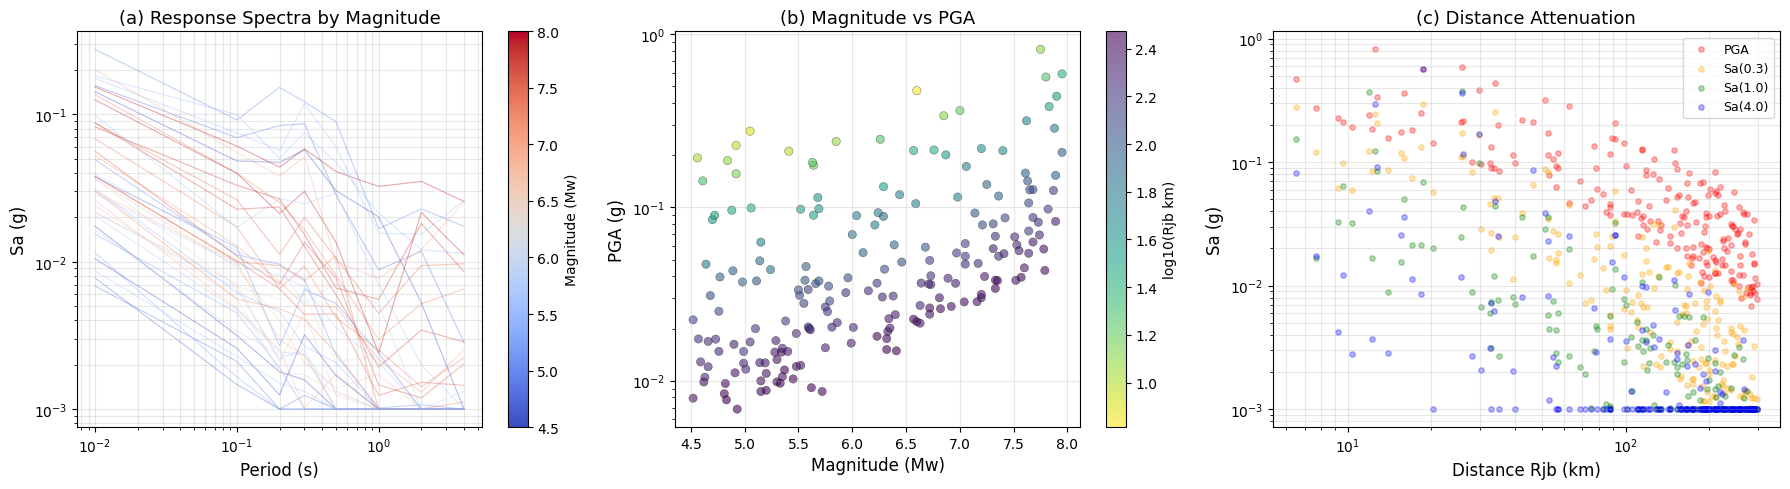

In [3]:
# ───── Part 3: EDA - Sample Response Spectra ─────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# (a) Sample response spectra colored by magnitude
cmap = plt.cm.coolwarm
for i in range(0, n_samples, 5):  # Plot every 5th spectrum
    sa_vals = [df[label].iloc[i] for label in period_labels]
    color = cmap((magnitude[i] - 4.5) / 3.5)
    axes[0].loglog(periods, sa_vals, '-', color=color, alpha=0.4, linewidth=0.8)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(4.5, 8.0))
plt.colorbar(sm, ax=axes[0], label='Magnitude (Mw)')
axes[0].set_xlabel('Period (s)', fontsize=12)
axes[0].set_ylabel('Sa (g)', fontsize=12)
axes[0].set_title('(a) Response Spectra by Magnitude', fontsize=13)
axes[0].grid(True, alpha=0.3, which='both')

# (b) Magnitude vs PGA
sc = axes[1].scatter(df['magnitude'], df['PGA'], c=np.log10(df['rjb_km']),
                     cmap='viridis_r', alpha=0.6, edgecolors='k', linewidth=0.3)
plt.colorbar(sc, ax=axes[1], label='log10(Rjb km)')
axes[1].set_xlabel('Magnitude (Mw)', fontsize=12)
axes[1].set_ylabel('PGA (g)', fontsize=12)
axes[1].set_title('(b) Magnitude vs PGA', fontsize=13)
axes[1].set_yscale('log')
axes[1].grid(True, alpha=0.3)

# (c) Distance attenuation at different periods
for label, color in zip(['PGA', 'Sa(0.3)', 'Sa(1.0)', 'Sa(4.0)'],
                        ['red', 'orange', 'green', 'blue']):
    axes[2].scatter(df['rjb_km'], df[label], alpha=0.3, c=color, s=15, label=label)
axes[2].set_xlabel('Distance Rjb (km)', fontsize=12)
axes[2].set_ylabel('Sa (g)', fontsize=12)
axes[2].set_title('(c) Distance Attenuation', fontsize=13)
axes[2].set_xscale('log')
axes[2].set_yscale('log')
axes[2].legend(fontsize=9)
axes[2].grid(True, alpha=0.3, which='both')

plt.tight_layout()
plt.savefig('eda_spectra.png', dpi=150, bbox_inches='tight')
plt.show()

In [4]:
# ───── Part 4: Data Preparation ─────
features = ['magnitude', 'rjb_km', 'vs30_m_s', 'ztor_km', 'rake_deg', 'z1pt0_m']
targets = period_labels

X = df[features].values
Y = np.log(df[targets].values)  # Log-transform Sa for better ML performance

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

scaler_X = StandardScaler()
X_train_sc = scaler_X.fit_transform(X_train)
X_test_sc = scaler_X.transform(X_test)

print(f'Training: {X_train.shape[0]} samples')
print(f'Test:     {X_test.shape[0]} samples')
print(f'Output dimensions: {Y_train.shape[1]} periods')

Training: 160 samples
Test:     40 samples
Output dimensions: 8 periods


In [5]:
# ───── Part 5: Train Multi-Output Models ─────
models = {
    'Random Forest': MultiOutputRegressor(
        RandomForestRegressor(n_estimators=200, max_depth=12, random_state=42)),
    'Gradient Boosting': MultiOutputRegressor(
        GradientBoostingRegressor(n_estimators=200, max_depth=5,
                                  learning_rate=0.05, random_state=42)),
    'MLP': MLPRegressor(hidden_layer_sizes=(128, 64, 32), max_iter=500,
                        random_state=42, learning_rate='adaptive')
}

predictions = {}
results = []

for name, model in models.items():
    if name == 'MLP':
        model.fit(X_train_sc, Y_train)
        Y_pred = model.predict(X_test_sc)
    else:
        model.fit(X_train, Y_train)
        Y_pred = model.predict(X_test)

    predictions[name] = Y_pred

    # Compute metrics per period
    r2_per_period = [r2_score(Y_test[:, i], Y_pred[:, i]) for i in range(len(targets))]
    rmse_per_period = [np.sqrt(mean_squared_error(Y_test[:, i], Y_pred[:, i]))
                       for i in range(len(targets))]

    mean_r2 = np.mean(r2_per_period)
    mean_rmse = np.mean(rmse_per_period)
    results.append({'Model': name, 'Mean_R2': mean_r2, 'Mean_RMSE_lnSa': mean_rmse})

    print(f'{name} - Mean R2: {mean_r2:.4f}, Mean RMSE(ln Sa): {mean_rmse:.4f}')

Random Forest - Mean R2: 0.8858, Mean RMSE(ln Sa): 0.4240


Gradient Boosting - Mean R2: 0.8486, Mean RMSE(ln Sa): 0.4802


MLP - Mean R2: 0.8598, Mean RMSE(ln Sa): 0.4716


In [6]:
# ───── Part 6: GMPE Baseline ─────
Y_pred_gmpe = np.zeros_like(Y_test)
for i, T in enumerate(periods):
    sa_gmpe = compute_sa(X_test[:, 0], X_test[:, 1], X_test[:, 2], T, X_test[:, 3])
    Y_pred_gmpe[:, i] = np.log(np.clip(sa_gmpe, 0.001, 5.0))

r2_gmpe = [r2_score(Y_test[:, i], Y_pred_gmpe[:, i]) for i in range(len(targets))]
rmse_gmpe = [np.sqrt(mean_squared_error(Y_test[:, i], Y_pred_gmpe[:, i]))
             for i in range(len(targets))]

results.append({'Model': 'GMPE Baseline', 'Mean_R2': np.mean(r2_gmpe),
                'Mean_RMSE_lnSa': np.mean(rmse_gmpe)})
predictions['GMPE'] = Y_pred_gmpe

print(f'GMPE Baseline - Mean R2: {np.mean(r2_gmpe):.4f}, '
      f'Mean RMSE(ln Sa): {np.mean(rmse_gmpe):.4f}')

GMPE Baseline - Mean R2: 0.9358, Mean RMSE(ln Sa): 0.3176


In [7]:
# ───── Part 7: Results Summary ─────
results_df = pd.DataFrame(results).sort_values('Mean_R2', ascending=False)
print('\n=== Model Comparison ===')
print(results_df.to_string(index=False))


=== Model Comparison ===
            Model  Mean_R2  Mean_RMSE_lnSa
    GMPE Baseline 0.935839        0.317642
    Random Forest 0.885788        0.424008
              MLP 0.859795        0.471593
Gradient Boosting 0.848629        0.480193


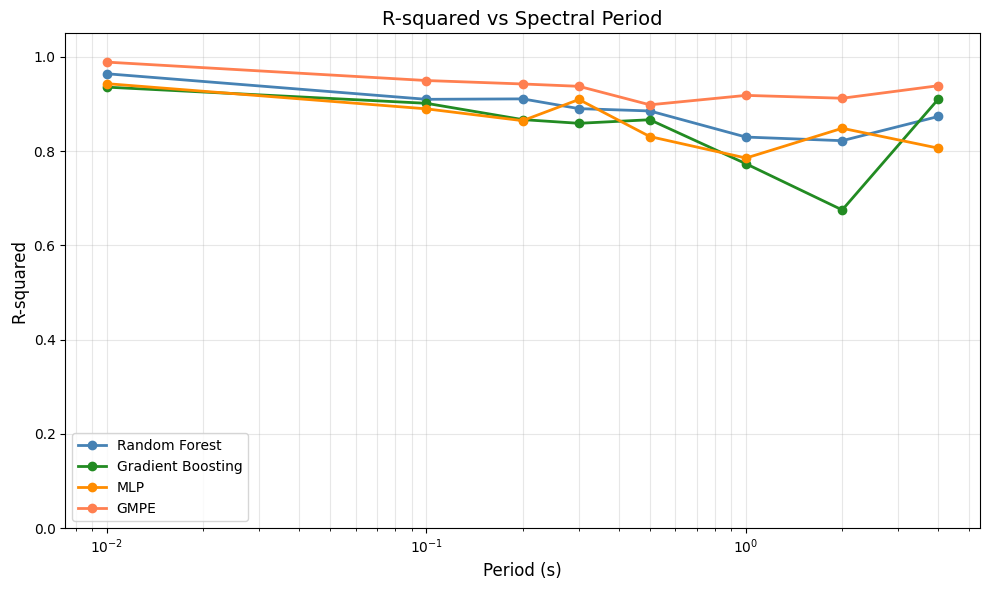

In [8]:
# ───── Part 8: R-squared per Period ─────
fig, ax = plt.subplots(figsize=(10, 6))
colors_line = ['steelblue', 'forestgreen', 'darkorange', 'coral']

for idx, (name, Y_pred) in enumerate(predictions.items()):
    r2_vals = [r2_score(Y_test[:, i], Y_pred[:, i]) for i in range(len(targets))]
    ax.plot(periods, r2_vals, 'o-', color=colors_line[idx], label=name,
            linewidth=2, markersize=6)

ax.set_xlabel('Period (s)', fontsize=12)
ax.set_ylabel('R-squared', fontsize=12)
ax.set_title('R-squared vs Spectral Period', fontsize=14)
ax.set_xscale('log')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3, which='both')
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.savefig('r2_per_period.png', dpi=150, bbox_inches='tight')
plt.show()

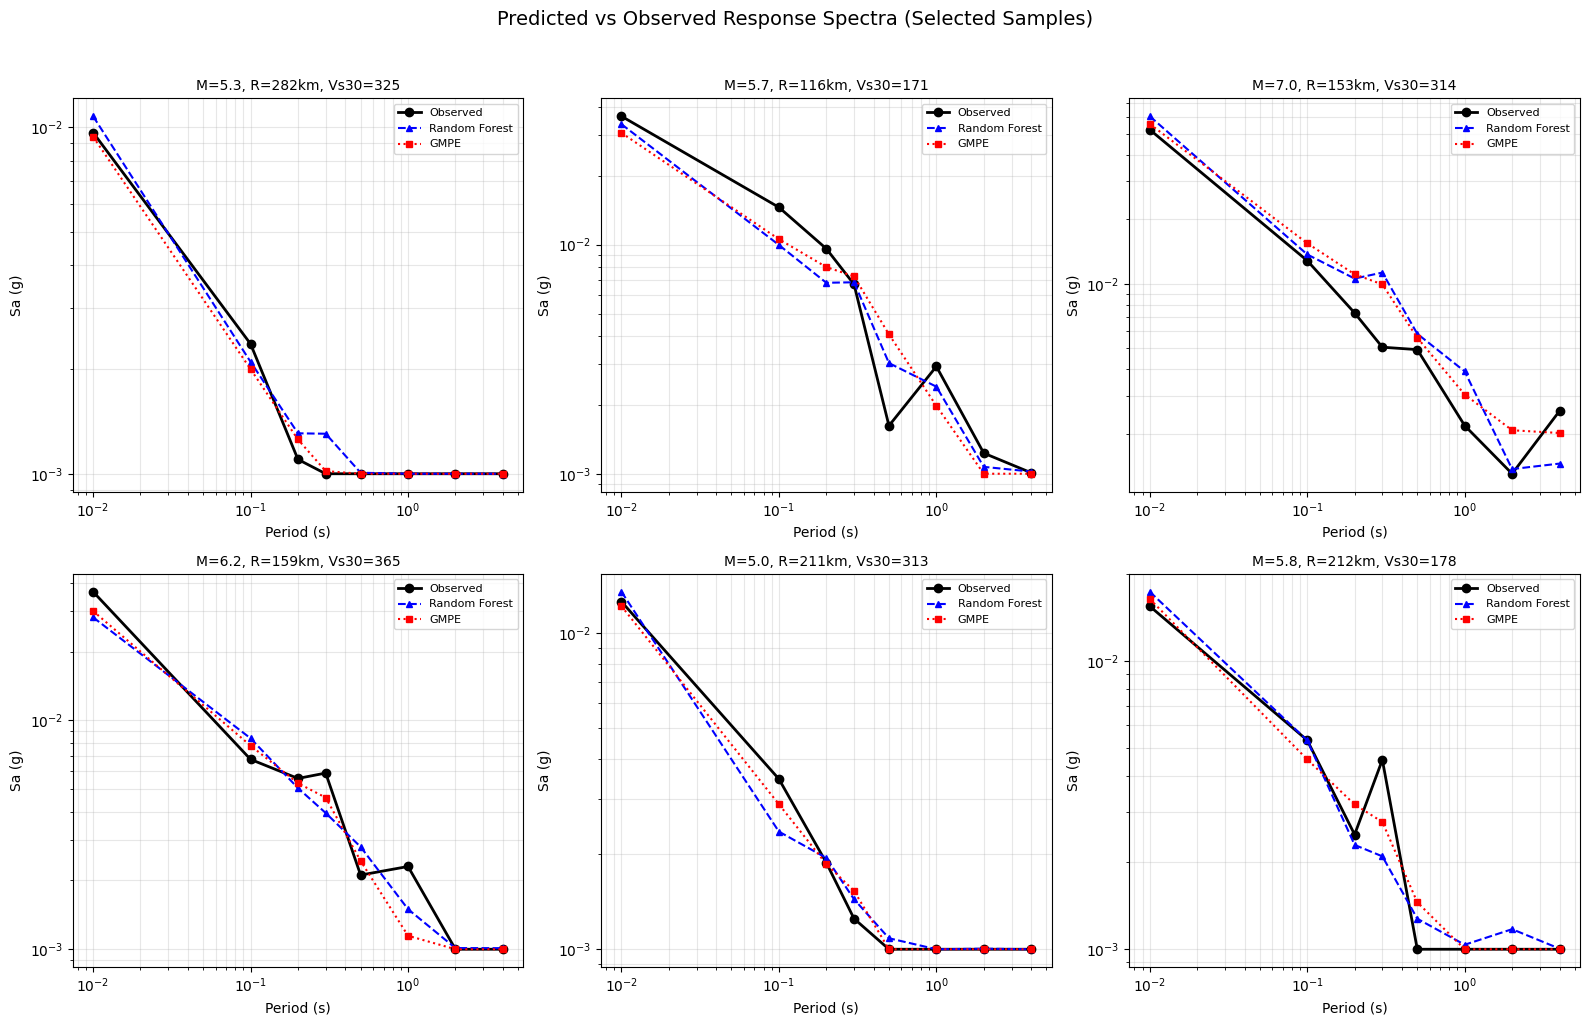

In [9]:
# ───── Part 9: Predicted vs Observed Spectra ─────
# Select best model
ml_results = results_df[results_df['Model'] != 'GMPE Baseline']
best_name = ml_results.iloc[0]['Model']   # best ML model (GMPE is plotted separately)
best_pred = predictions[best_name]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
sample_indices = np.random.choice(len(Y_test), 6, replace=False)

for idx, si in enumerate(sample_indices):
    ax = axes[idx // 3, idx % 3]
    sa_obs = np.exp(Y_test[si])
    sa_pred = np.exp(best_pred[si])
    sa_gmpe = np.exp(Y_pred_gmpe[si])

    ax.loglog(periods, sa_obs, 'ko-', markersize=6, label='Observed', linewidth=2)
    ax.loglog(periods, sa_pred, 'b^--', markersize=5, label=f'{best_name}', linewidth=1.5)
    ax.loglog(periods, sa_gmpe, 'rs:', markersize=5, label='GMPE', linewidth=1.5)

    ax.set_xlabel('Period (s)', fontsize=10)
    ax.set_ylabel('Sa (g)', fontsize=10)
    ax.set_title(f'M={X_test[si, 0]:.1f}, R={X_test[si, 1]:.0f}km, Vs30={X_test[si, 2]:.0f}',
                 fontsize=10)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3, which='both')

plt.suptitle('Predicted vs Observed Response Spectra (Selected Samples)', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('spectra_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

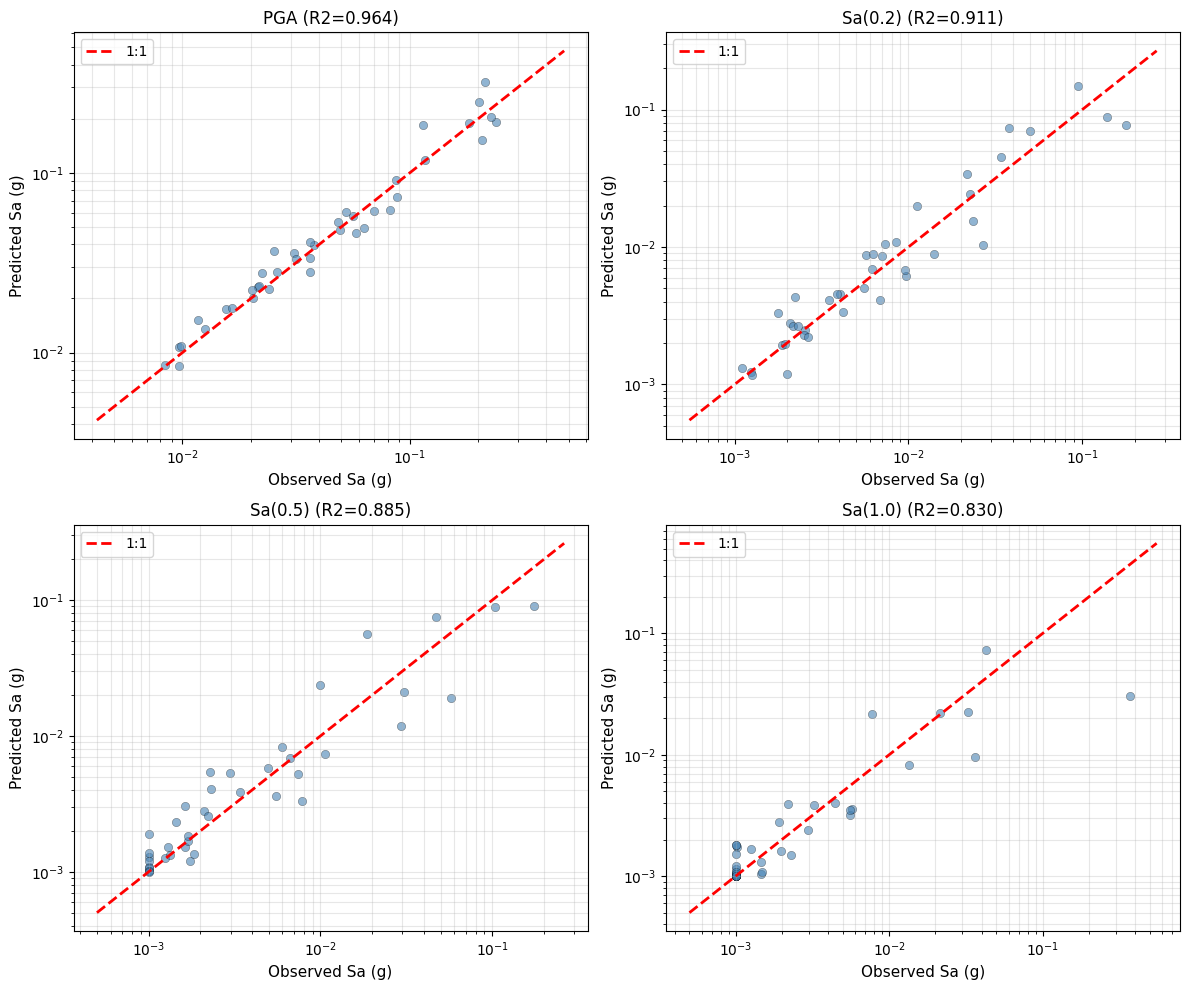

In [10]:
# ───── Part 10: Predicted vs Observed at Key Periods ─────
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
key_periods_idx = [0, 2, 4, 5]  # PGA, Sa(0.2), Sa(0.5), Sa(1.0)

for idx, pi in enumerate(key_periods_idx):
    ax = axes[idx // 2, idx % 2]
    obs = np.exp(Y_test[:, pi])
    pred = np.exp(best_pred[:, pi])
    ax.scatter(obs, pred, alpha=0.6, edgecolors='k', linewidth=0.3, c='steelblue')
    vmin = min(obs.min(), pred.min()) * 0.5
    vmax = max(obs.max(), pred.max()) * 1.5
    ax.plot([vmin, vmax], [vmin, vmax], 'r--', linewidth=2, label='1:1')
    ax.set_xlabel('Observed Sa (g)', fontsize=11)
    ax.set_ylabel('Predicted Sa (g)', fontsize=11)
    r2 = r2_score(Y_test[:, pi], best_pred[:, pi])
    ax.set_title(f'{targets[pi]} (R2={r2:.3f})', fontsize=12)
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.legend()
    ax.grid(True, alpha=0.3, which='both')

plt.tight_layout()
plt.savefig('pred_vs_obs_periods.png', dpi=150, bbox_inches='tight')
plt.show()

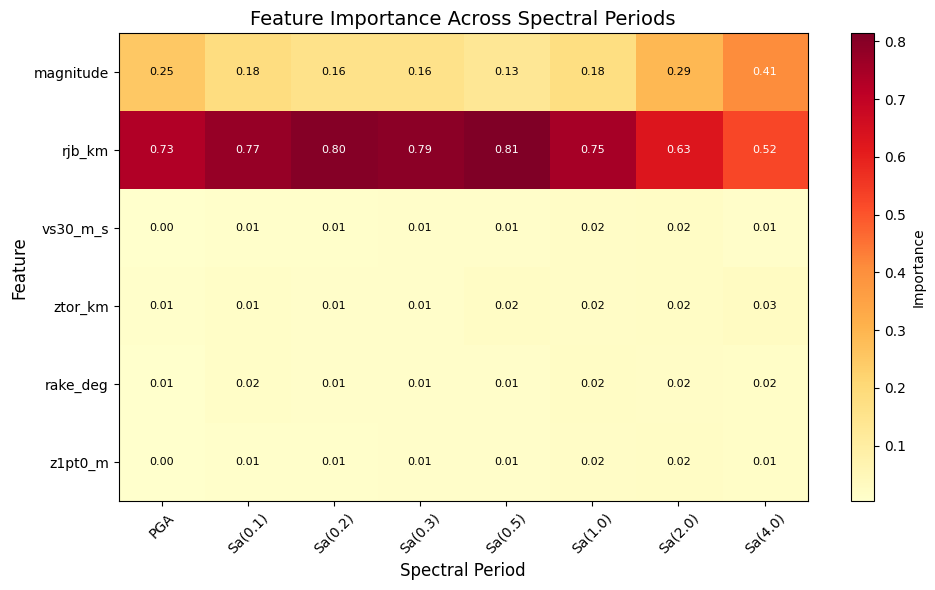

In [11]:
# ───── Part 11: Feature Importance ─────
# Get feature importance from RF for each period
rf_model = models['Random Forest']
importance_matrix = np.array([est.feature_importances_
                              for est in rf_model.estimators_])

fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(importance_matrix.T, aspect='auto', cmap='YlOrRd')
ax.set_xticks(range(len(targets)))
ax.set_xticklabels(targets, rotation=45)
ax.set_yticks(range(len(features)))
ax.set_yticklabels(features)
ax.set_xlabel('Spectral Period', fontsize=12)
ax.set_ylabel('Feature', fontsize=12)
ax.set_title('Feature Importance Across Spectral Periods', fontsize=14)

# Add text annotations
for i in range(len(features)):
    for j in range(len(targets)):
        ax.text(j, i, f'{importance_matrix[j, i]:.2f}',
                ha='center', va='center', fontsize=8,
                color='white' if importance_matrix[j, i] > 0.3 else 'black')

plt.colorbar(im, label='Importance')
plt.tight_layout()
plt.savefig('feature_importance_periods.png', dpi=150, bbox_inches='tight')
plt.show()

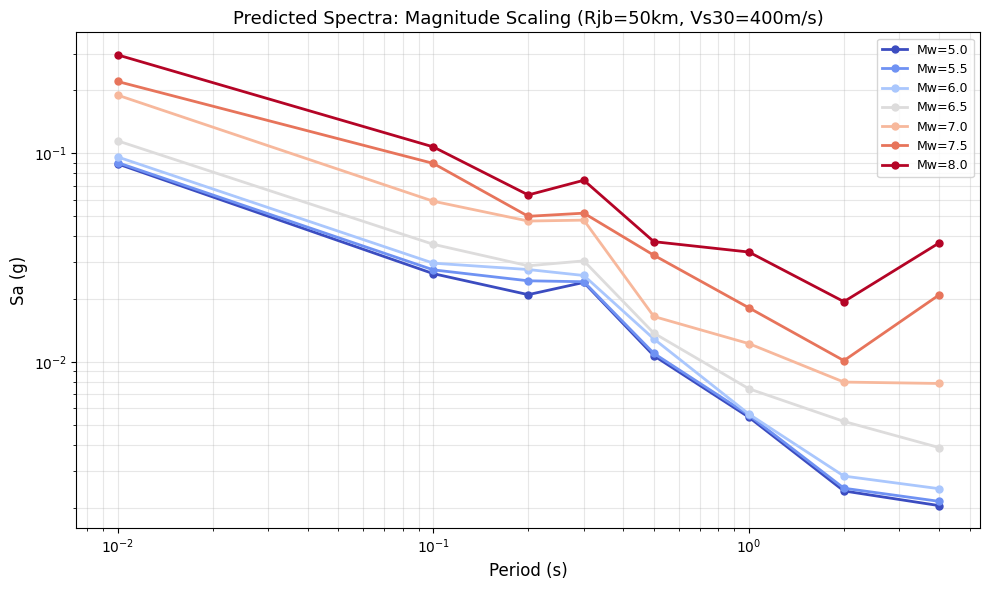

In [12]:
# ───── Part 12: Magnitude Scaling Check ─────
# Predict spectra for varying magnitudes at fixed distance and site
mag_range = np.arange(5.0, 8.1, 0.5)
fixed_params = np.array([[m, 50, 400, 5, 0, 200] for m in mag_range])

rf_model_trained = models['Random Forest']
Y_pred_mag = rf_model_trained.predict(fixed_params)

fig, ax = plt.subplots(figsize=(10, 6))
cmap = plt.cm.coolwarm
for i, m in enumerate(mag_range):
    sa_vals = np.exp(Y_pred_mag[i])
    color = cmap((m - 5.0) / 3.0)
    ax.loglog(periods, sa_vals, 'o-', color=color, linewidth=2, markersize=5,
             label=f'Mw={m:.1f}')

ax.set_xlabel('Period (s)', fontsize=12)
ax.set_ylabel('Sa (g)', fontsize=12)
ax.set_title('Predicted Spectra: Magnitude Scaling (Rjb=50km, Vs30=400m/s)', fontsize=13)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3, which='both')
plt.tight_layout()
plt.savefig('magnitude_scaling.png', dpi=150, bbox_inches='tight')
plt.show()

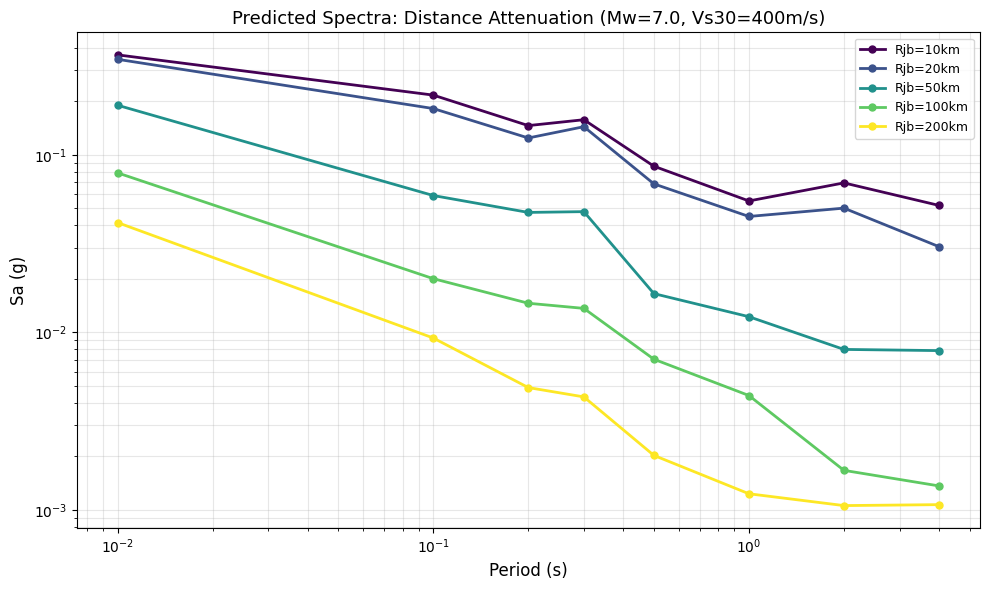

In [13]:
# ───── Part 13: Distance Attenuation Check ─────
dist_range = [10, 20, 50, 100, 200]
fixed_params_d = np.array([[7.0, r, 400, 5, 0, 200] for r in dist_range])

Y_pred_dist = rf_model_trained.predict(fixed_params_d)

fig, ax = plt.subplots(figsize=(10, 6))
colors_d = plt.cm.viridis(np.linspace(0, 1, len(dist_range)))
for i, r in enumerate(dist_range):
    sa_vals = np.exp(Y_pred_dist[i])
    ax.loglog(periods, sa_vals, 'o-', color=colors_d[i], linewidth=2,
             markersize=5, label=f'Rjb={r}km')

ax.set_xlabel('Period (s)', fontsize=12)
ax.set_ylabel('Sa (g)', fontsize=12)
ax.set_title('Predicted Spectra: Distance Attenuation (Mw=7.0, Vs30=400m/s)', fontsize=13)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3, which='both')
plt.tight_layout()
plt.savefig('distance_attenuation.png', dpi=150, bbox_inches='tight')
plt.show()

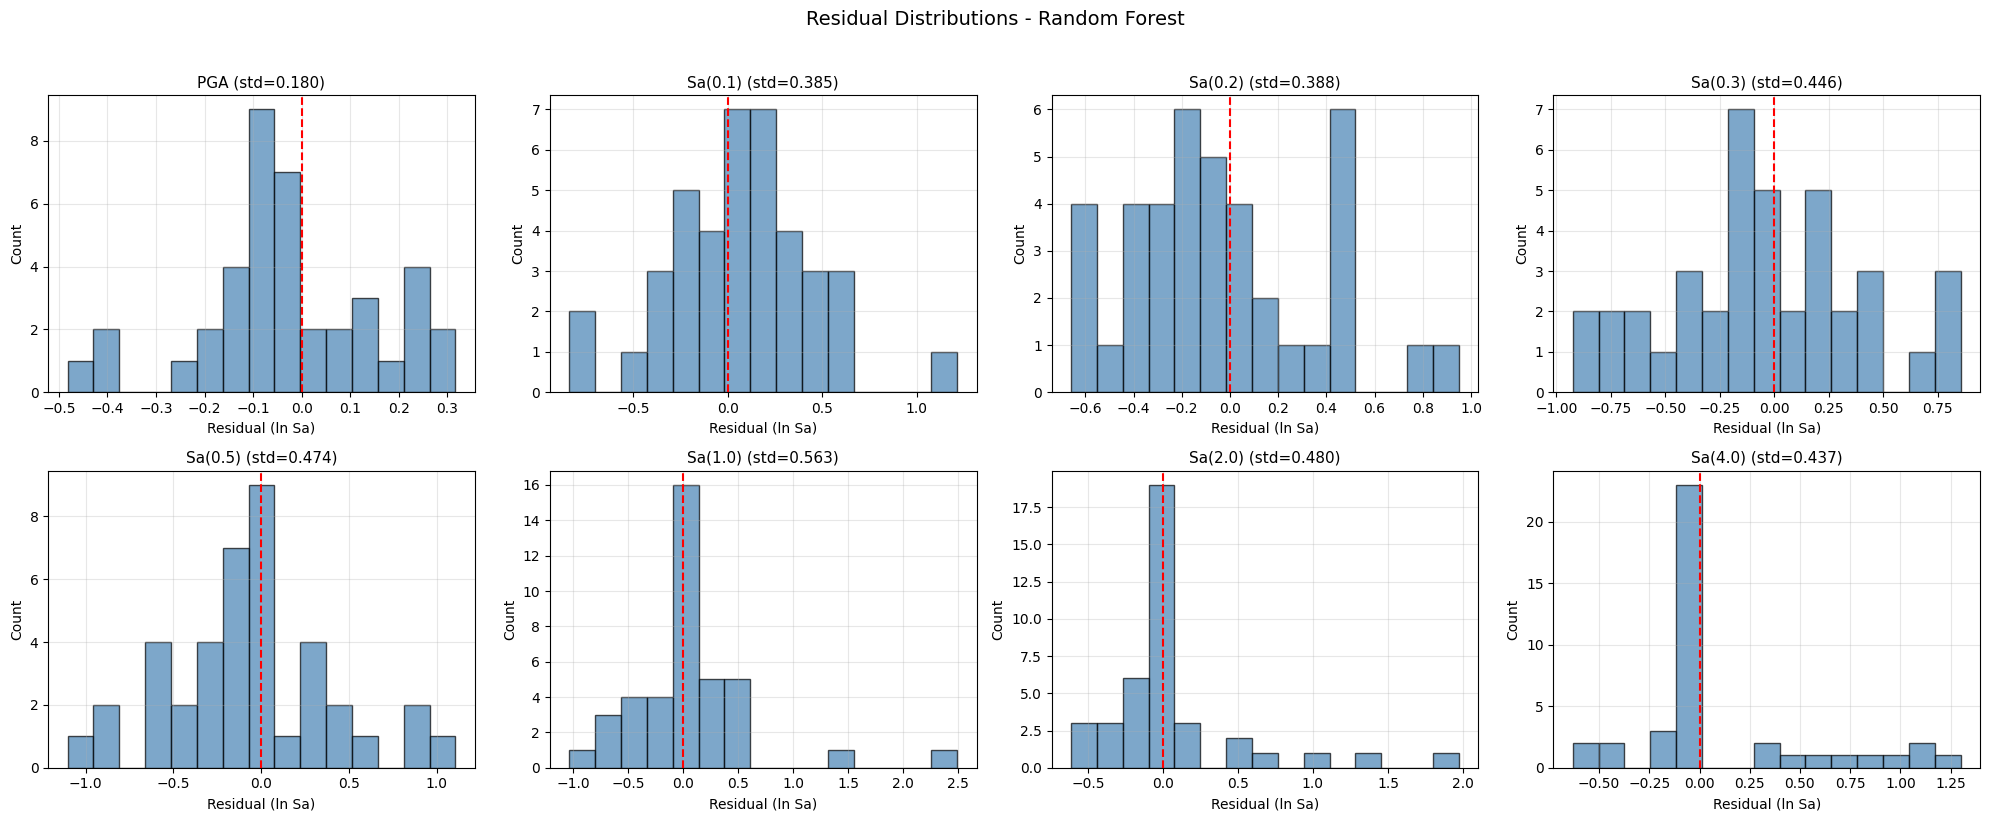

In [14]:
# ───── Part 14: Residual Analysis ─────
fig, axes = plt.subplots(2, 4, figsize=(20, 8))

for i, (label, ax) in enumerate(zip(targets, axes.ravel())):
    residuals = Y_test[:, i] - best_pred[:, i]
    ax.hist(residuals, bins=15, color='steelblue', edgecolor='black', alpha=0.7)
    ax.axvline(0, color='red', linestyle='--', linewidth=1.5)
    ax.set_xlabel('Residual (ln Sa)', fontsize=10)
    ax.set_ylabel('Count', fontsize=10)
    ax.set_title(f'{label} (std={residuals.std():.3f})', fontsize=11)
    ax.grid(True, alpha=0.3)

plt.suptitle(f'Residual Distributions - {best_name}', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('residuals.png', dpi=150, bbox_inches='tight')
plt.show()

## Key Takeaways

1. **Multi-output ML models can predict full response spectra** simultaneously, maintaining physical consistency across spectral periods.

2. **Magnitude and distance are the dominant features** across all periods, while Vs30 becomes more important at longer periods -- consistent with seismological principles.

3. **ML models capture the correct magnitude scaling and distance attenuation trends**, showing physically reasonable spectral shapes.

4. **Random Forest and Gradient Boosting outperform the simplified GMPE** because they can learn complex non-linear interactions between parameters.

5. **Residual standard deviations are approximately uniform across periods**, suggesting consistent prediction quality -- an important property for probabilistic seismic hazard analysis.

## Next Steps

- Train on real NGA-West2 ground motion database
- Include style-of-faulting and hanging wall effects
- Develop region-specific models for different tectonic settings
- Quantify epistemic uncertainty using model ensembles
- Integrate into probabilistic seismic hazard analysis (PSHA)